# Projet 6 – Delta-Hedging : modèle Python (Semaine 2)
**Groupe 6 · Rôle : Quant / Data**

Ce notebook : (1) simule des trajectoires GBM, (2) réalise la couverture delta jour par jour, (3) répète sur 1 000 trajectoires, (4) compare les fréquences de rééquilibrage, (5) teste σ_réelle ≠ σ_pricing (Gamma-scalping), (6) télécharge AAPL pour le Random Forest.

## 0. Imports et paramètres

In [1]:
import sys, os
sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.pricing import bs_price, greeks, simulate_gbm, delta_hedge, delta_hedge_paths

os.makedirs("../docs/figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

S0, K, T, r = 100.0, 100.0, 1.0, 0.03
mu = 0.05
sigma = 0.20
n = 252
M = 1000
SEED = 42
print("Prime Black-Scholes :", round(bs_price(S0, K, T, r, sigma, "call"), 4))

Prime Black-Scholes : 9.4134


## 1. Une trajectoire : prix, Delta et P&L

P&L final (1 trajectoire) = 0.7222


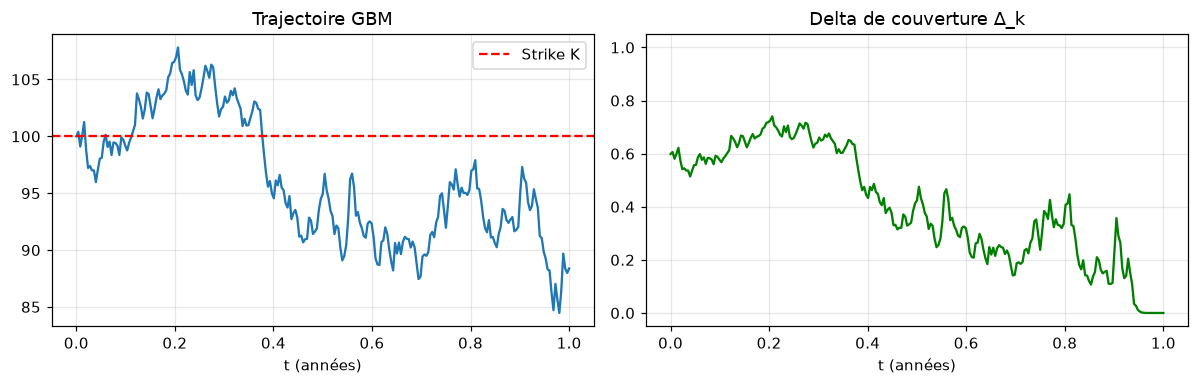

In [2]:
S = simulate_gbm(S0, mu, sigma, T, n, n_paths=1, seed=SEED)[0]
t = np.linspace(0, T, n + 1)
deltas = [greeks(S[k], K, max(T - t[k], 1e-6), r, sigma)["delta"] for k in range(n + 1)]
pnl_1 = delta_hedge(S, K, T, r, sigma)
print(f"P&L final (1 trajectoire) = {pnl_1:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(t, S); ax[0].axhline(K, color="r", ls="--", label="Strike K"); ax[0].set_title("Trajectoire GBM"); ax[0].set_xlabel("t (années)"); ax[0].legend()
ax[1].plot(t, deltas, color="green"); ax[1].set_title("Delta de couverture Δ_k"); ax[1].set_xlabel("t (années)"); ax[1].set_ylim(-0.05, 1.05)
plt.tight_layout(); plt.savefig("../docs/figures/01_trajectoire_delta.png"); plt.show()

## 2. 1 000 trajectoires : histogramme du P&L final

Moyenne = -0.0018 | Écart-type = 0.4180 | Quantile 5 % = -0.6879


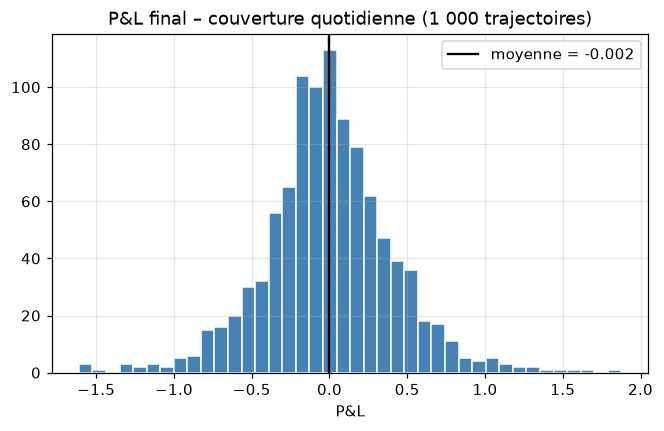

In [3]:
paths = simulate_gbm(S0, mu, sigma, T, n, n_paths=M, seed=SEED)
pnl = delta_hedge_paths(paths, K, T, r, sigma, every=1)
print(f"Moyenne = {pnl.mean():.4f} | Écart-type = {pnl.std():.4f} | Quantile 5 % = {np.quantile(pnl, 0.05):.4f}")

plt.figure(figsize=(7, 4))
plt.hist(pnl, bins=40, color="steelblue", edgecolor="white")
plt.axvline(0, color="r", ls="--"); plt.axvline(pnl.mean(), color="k", label=f"moyenne = {pnl.mean():.3f}")
plt.title("P&L final – couverture quotidienne (1 000 trajectoires)"); plt.xlabel("P&L"); plt.legend()
plt.savefig("../docs/figures/02_hist_pnl.png"); plt.show()

## 3. Fréquences de rééquilibrage : quotidienne, hebdomadaire, mensuelle

                    Moyenne  Écart-type  Quantile 5 %
Quotidienne (252)   -0.0018      0.4180       -0.6879
Hebdomadaire (~52)  -0.0197      0.9079       -1.5691
Mensuelle (12)       0.0448      1.9202       -3.1517

Ratio mensuel/hebdo   : 2.11   (théorie ≈ 2,1)
Ratio hebdo/quotidien : 2.17   (théorie ≈ 2,2)
Ratio mensuel/quotid. : 4.59   (théorie ≈ 4,6)


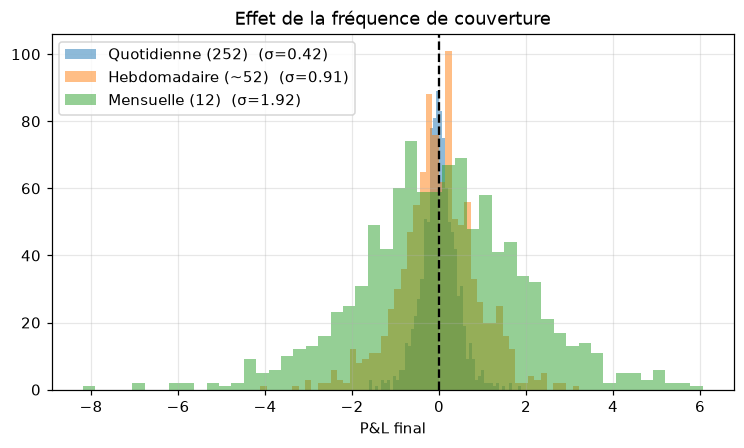

In [4]:
freqs = {"Quotidienne (252)": 1, "Hebdomadaire (~52)": 5, "Mensuelle (12)": 21}
res = {}
for name, every in freqs.items():
    res[name] = delta_hedge_paths(paths, K, T, r, sigma, every=every)

tab = pd.DataFrame({k: {"Moyenne": v.mean(), "Écart-type": v.std(), "Quantile 5 %": np.quantile(v, 0.05)} for k, v in res.items()}).T
print(tab.round(4))

std_q, std_h, std_m = (res[k].std() for k in freqs)
print(f"\nRatio mensuel/hebdo   : {std_m/std_h:.2f}   (théorie ≈ 2,1)")
print(f"Ratio hebdo/quotidien : {std_h/std_q:.2f}   (théorie ≈ 2,2)")
print(f"Ratio mensuel/quotid. : {std_m/std_q:.2f}   (théorie ≈ 4,6)")

plt.figure(figsize=(8, 4.2))
for name, v in res.items():
    plt.hist(v, bins=50, alpha=0.5, label=f"{name}  (σ={v.std():.2f})")
plt.axvline(0, color="k", ls="--"); plt.legend(); plt.xlabel("P&L final"); plt.title("Effet de la fréquence de couverture")
plt.savefig("../docs/figures/03_frequences.png"); plt.show()

### Vérification de la loi en 1/√n

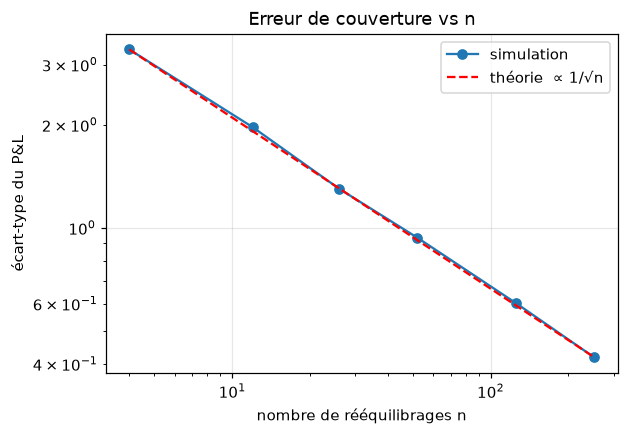

     n  écart-type
0    4      3.3213
1   12      1.9696
2   26      1.2996
3   52      0.9366
4  126      0.6010
5  252      0.4180


In [5]:
ns = [4, 12, 26, 52, 126, 252]
stds = []
for nb in ns:
    p = simulate_gbm(S0, mu, sigma, T, nb, n_paths=M, seed=SEED)
    stds.append(delta_hedge_paths(p, K, T, r, sigma, every=1).std())
stds = np.array(stds)
plt.figure(figsize=(6, 4))
plt.loglog(ns, stds, "o-", label="simulation")
plt.loglog(ns, stds[0] * np.sqrt(ns[0] / np.array(ns)), "r--", label="théorie  ∝ 1/√n")
plt.xlabel("nombre de rééquilibrages n"); plt.ylabel("écart-type du P&L"); plt.legend(); plt.title("Erreur de couverture vs n")
plt.savefig("../docs/figures/04_loi_racine_n.png"); plt.show()
print(pd.DataFrame({"n": ns, "écart-type": stds.round(4)}))

## 4. Sensibilité σ_réelle ≠ σ_pricing (Gamma-scalping)

   σ_réelle  P&L moyen  Écart-type
0      0.10     3.8793      1.0935
1      0.15     1.9587      0.7390
2      0.20    -0.0018      0.4180
3      0.25    -1.9556      0.9716
4      0.30    -3.9059      1.9103


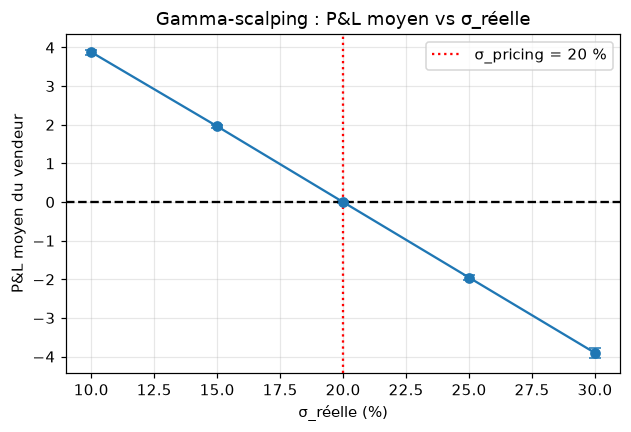

In [6]:
sig_pricing = 0.20
sig_reelles = [0.10, 0.15, 0.20, 0.25, 0.30]
rows = []
for sr in sig_reelles:
    p = simulate_gbm(S0, mu, sr, T, n, n_paths=M, seed=SEED)
    v = delta_hedge_paths(p, K, T, r, sig_pricing, every=1)
    rows.append({"σ_réelle": sr, "P&L moyen": v.mean(), "Écart-type": v.std()})
sens = pd.DataFrame(rows); print(sens.round(4))

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.errorbar(sens["σ_réelle"] * 100, sens["P&L moyen"], yerr=sens["Écart-type"] / np.sqrt(M) * 1.96, fmt="o-", capsize=4)
ax.axhline(0, color="k", ls="--"); ax.axvline(sig_pricing * 100, color="r", ls=":", label="σ_pricing = 20 %")
ax.set_xlabel("σ_réelle (%)"); ax.set_ylabel("P&L moyen du vendeur"); ax.set_title("Gamma-scalping : P&L moyen vs σ_réelle"); ax.legend()
plt.savefig("../docs/figures/05_sensibilite_sigma.png"); plt.show()

## 5. Données AAPL pour le Random Forest (yfinance)

In [7]:
from src.data import get_ohlcv, historical_vol
try:
    aapl = get_ohlcv("AAPL", "5y")
    os.makedirs("../data", exist_ok=True)
    aapl.to_csv("../data/aapl.csv")
    print(aapl.tail(3))
    print(f"\n{len(aapl)} jours | vol historique annualisée = {historical_vol(aapl['Close']):.2%}")
except Exception as e:
    print("Téléchargement impossible pour l'instant :", e)

$AAPL: possibly delisted; no price data found  (period=5y)


                                 Open        High         Low       Close  \
Date                                                                        
2026-11-17 00:00:00-05:00  352.829987  355.359985  349.670013  351.910004   
2026-11-18 00:00:00-05:00  351.940002  356.420013  351.470001  352.450012   
2026-11-19 00:00:00-05:00  352.910004  355.279999  346.470001  349.209991   

                             Volume  
Date                                 
2026-11-17 00:00:00-05:00  37407500  
2026-11-18 00:00:00-05:00  34209900  
2026-11-19 00:00:00-05:00  40795500  

1254 jours | vol historique annualisée = 28.05%


## 6. Conclusions
- La moyenne du P&L final est proche de 0 : la couverture delta neutralise le risque en moyenne.
- L'écart-type diminue quand on rééquilibre plus souvent (loi en 1/√n).
- Si σ_réelle > σ_pricing, le vendeur perd en moyenne ; si σ_réelle < σ_pricing, il gagne (Gamma-scalping).